# Movie Recommender System: Exploration and Model Comparison

This notebook explores the MovieLens 1M ratings and compares the project's trained SVD and Probabilistic Matrix Factorization (PMF) recommenders. It uses the project utilities and saved model artifacts so the analysis stays consistent with the training pipeline.

From the repository root, install `requirements.txt` and generate the artifacts first:

```bash
python utils/matrix_creation.py
python -m models.svd_model
python -m models.pmf_model
```

Unrated user/movie pairs are missing observations, not zero-star ratings. Evaluation below uses only observed ratings from the held-out test split.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "utils").is_dir():
    raise RuntimeError("Run this notebook with the repository root as the working directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from utils.data_loader import load_matrix_ids, load_movies, load_ratings, load_users
from utils.data_split import split_data
from utils.evaluation import evaluate_rmse
from utils.recommendation import PREDICTION_PATHS, generate_recommendations

ratings = load_ratings()
users = load_users()
movies = load_movies()
train_ratings, test_ratings = split_data(ratings)
user_ids, movie_ids = load_matrix_ids()

print(f"Ratings: {len(ratings):,} | users: {len(users):,} | movies: {len(movies):,}")
print(f"Train: {len(train_ratings):,} | test: {len(test_ratings):,} (random_state=42)")
print(ratings.head().to_string(index=False))

Ratings: 1,000,209 | users: 6,040 | movies: 3,883
Train: 800,167 | test: 200,042 (random_state=42)
 UserID  MovieID  Rating  Timestamp
      1     1193       5  978300760
      1      661       3  978302109
      1      914       3  978301968
      1     3408       4  978300275
      1     2355       5  978824291


## Rating data exploration

The dataset has integer ratings from 1 to 5. The plots below show the rating distribution and how many ratings users have contributed.

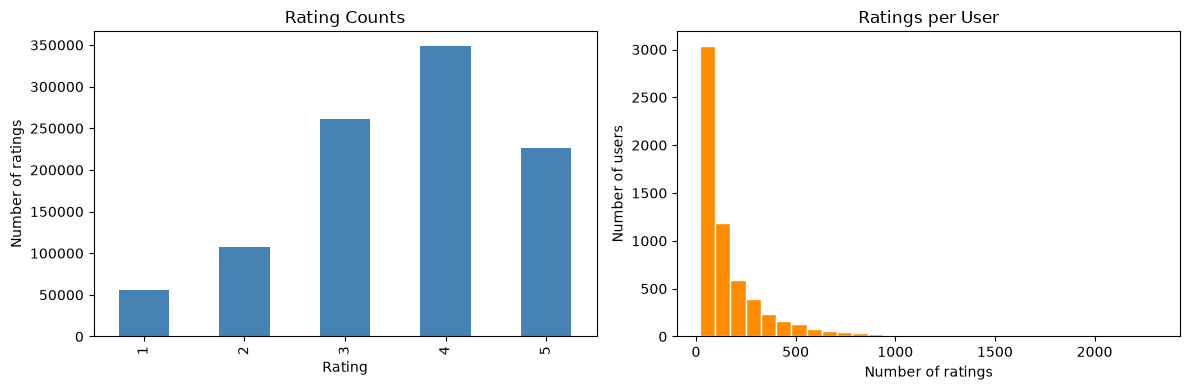

Mean rating: 3.58; median ratings per user: 96


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ratings["Rating"].value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Rating Counts", xlabel="Rating", ylabel="Number of ratings")
user_rating_counts = ratings.groupby("UserID").size()
axes[1].hist(user_rating_counts, bins=30, color="darkorange", edgecolor="white")
axes[1].set(title="Ratings per User", xlabel="Number of ratings", ylabel="Number of users")
fig.tight_layout()
plt.show()

print(f"Mean rating: {ratings['Rating'].mean():.2f}; median ratings per user: {user_rating_counts.median():.0f}")

## User-item matrix and sparsity

`processed/user_item_matrix.csv` contains the training ratings centered around each user's training mean. Missing ratings are filled with zero deviation for factorization; this does not mean the user gave those movies a zero rating. The CSV is dense, so this cell reads only its header and user-ID column to avoid loading the full file.

In [3]:
matrix_path = PROJECT_ROOT / "processed" / "user_item_matrix.csv"
matrix_header = pd.read_csv(matrix_path, nrows=0)
matrix_shape = (sum(1 for _ in open(matrix_path, encoding="utf-8")) - 1, len(matrix_header.columns) - 1)
rating_density = len(train_ratings) / (matrix_shape[0] * matrix_shape[1])
print(f"Matrix shape: {matrix_shape[0]:,} users x {matrix_shape[1]:,} movies")
print(f"Observed training density: {rating_density:.2%}; sparsity: {1 - rating_density:.2%}")
print(f"Saved CSV size: {matrix_path.stat().st_size / (1024 ** 2):.1f} MiB")

Matrix shape: 6,040 users x 3,706 movies
Observed training density: 3.57%; sparsity: 96.43%
Saved CSV size: 87.9 MiB


## Compare held-out predictions

Load the full prediction matrices as memory-mapped arrays and calculate RMSE on the same held-out ratings. This keeps the evaluation focused on actual test observations rather than the filled matrix cells.

     Test RMSE
SVD   0.968158
PMF   0.889084


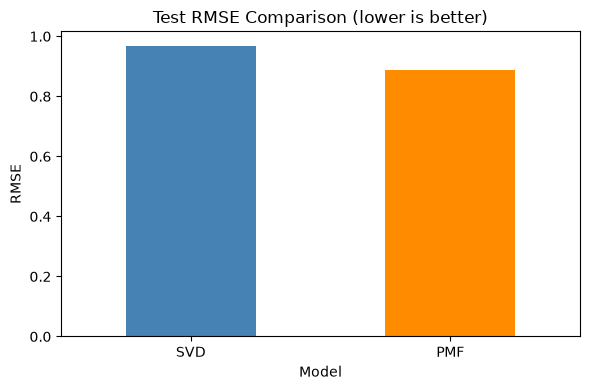

In [4]:
predictions = {}
model_rmse = {}
for model_name, prediction_path in PREDICTION_PATHS.items():
    if not prediction_path.is_file():
        raise FileNotFoundError(f"Missing {model_name.upper()} predictions: {prediction_path}. Train the model first.")
    predictions[model_name] = np.load(prediction_path, mmap_mode="r")
    if predictions[model_name].shape != (len(user_ids), len(movie_ids)):
        raise ValueError(f"Unexpected {model_name.upper()} prediction matrix shape")
    model_rmse[model_name.upper()] = evaluate_rmse(
        test_ratings, predictions[model_name], user_ids, movie_ids
    )

rmse_table = pd.DataFrame.from_dict(model_rmse, orient="index", columns=["Test RMSE"])
print(rmse_table.to_string())
fig, ax = plt.subplots(figsize=(6, 4))
rmse_table["Test RMSE"].plot.bar(ax=ax, color=["steelblue", "darkorange"])
ax.set(title="Test RMSE Comparison (lower is better)", xlabel="Model", ylabel="RMSE")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

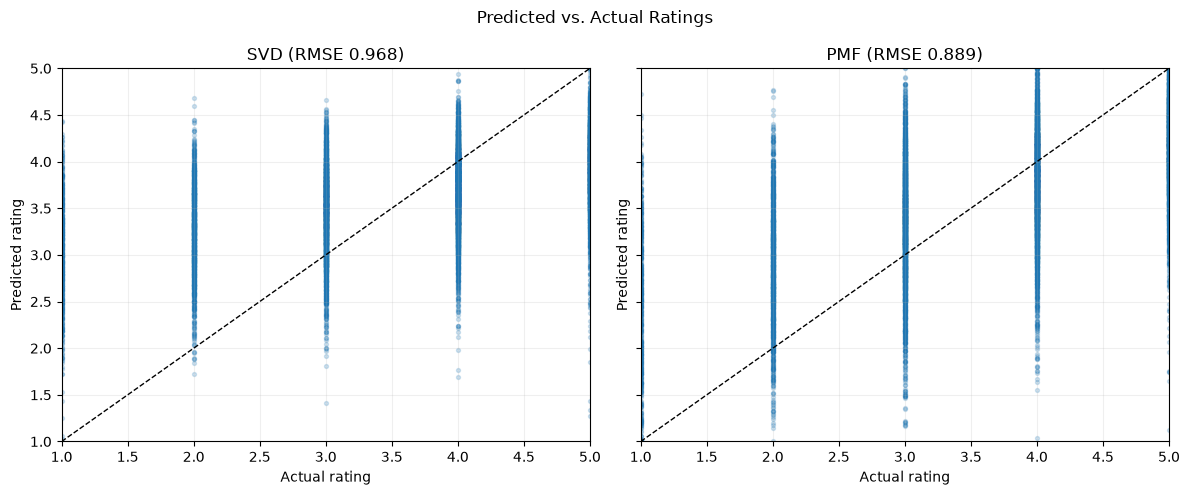

In [5]:
def predictions_for_ratings(test_rows, prediction_matrix):
    user_positions = pd.Series(np.arange(len(user_ids)), index=user_ids)
    movie_positions = pd.Series(np.arange(len(movie_ids)), index=movie_ids)
    row_indices = test_rows["UserID"].map(user_positions).to_numpy(dtype=np.int64)
    column_indices = test_rows["MovieID"].map(movie_positions).to_numpy(dtype=np.int64)
    return np.asarray(prediction_matrix[row_indices, column_indices])

sample_size = min(10_000, len(test_ratings))
sample_rows = np.random.default_rng(42).choice(len(test_ratings), sample_size, replace=False)
actual_sample = test_ratings["Rating"].to_numpy()[sample_rows]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, model_name in zip(axes, ("svd", "pmf")):
    estimates = predictions_for_ratings(test_ratings, predictions[model_name])[sample_rows]
    ax.scatter(actual_sample, estimates, alpha=0.2, s=8)
    ax.plot([1, 5], [1, 5], "k--", linewidth=1)
    ax.set(title=f"{model_name.upper()} (RMSE {model_rmse[model_name.upper()]:.3f})",
           xlabel="Actual rating", ylabel="Predicted rating", xlim=(1, 5), ylim=(1, 5))
    ax.grid(alpha=0.2)
fig.suptitle("Predicted vs. Actual Ratings")
fig.tight_layout()
plt.show()

## Compare recommendations for a user

Choose a user and inspect both their highest-rated movies and each model's top unseen recommendations. The recommendation utility excludes movies already rated by that user.

In [6]:
selected_user_id = 1
user_history = ratings.loc[ratings["UserID"] == selected_user_id]
if user_history.empty:
    raise ValueError(f"User {selected_user_id} does not exist in the ratings data")

top_rated = (user_history.sort_values(["Rating", "Timestamp"], ascending=[False, False])
             .merge(movies[["MovieID", "Title", "Genres"]], on="MovieID")
             .head(10)[["Title", "Genres", "Rating"]])
print(top_rated.to_string(index=False))

svd_recommendations = generate_recommendations(selected_user_id, "svd", top_n=10)
pmf_recommendations = generate_recommendations(selected_user_id, "pmf", top_n=10)
print("SVD recommendations")
display_svd = svd_recommendations.to_string(index=False)
print(display_svd)
print("PMF recommendations")
print(pmf_recommendations.to_string(index=False))

overlap = set(svd_recommendations["MovieID"]) & set(pmf_recommendations["MovieID"])
print(f"Top-10 overlap: {len(overlap)} movies")
print("Interpretation: SVD is a truncated linear factorization of the centered matrix; PMF learns user and item factors directly from observed ratings with regularization. Their different objectives and handling of missing observations can yield different rankings.")

                      Title                               Genres  Rating
          Pocahontas (1995) Animation|Children's|Musical|Romance       5
       Bug's Life, A (1998)          Animation|Children's|Comedy       5
Beauty and the Beast (1991)         Animation|Children's|Musical       5
           Toy Story (1995)          Animation|Children's|Comedy       5
    Schindler's List (1993)                            Drama|War       5
               Dumbo (1941)         Animation|Children's|Musical       5
             Ben-Hur (1959)               Action|Adventure|Drama       5
           Apollo 13 (1995)                                Drama       5
        Mary Poppins (1964)            Children's|Comedy|Musical       5
 Sound of Music, The (1965)                              Musical       5
SVD recommendations
 MovieID                     Title                  Genres  PredictedRating
     356       Forrest Gump (1994)      Comedy|Romance|War         4.328598
     110         Bravehea